# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot Map with focus villages

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Plot Map

In [2]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [3]:
# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

In [4]:
# set paired lists with name and lat/lon
# main villages
village_names_1 = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats_1 =  [66.257, 64.501, 63.879, 63.694,63.77611]
village_lons_1 =  [-166.072, -165.406, -160.790, -170.479,-171.70083]

# other villages names - 
# Utqiagvik, Wrainwright, Point Lay, Point Hope, Kivalina, Kotzebue, Deering, Wales, Teller, Brevig Mission, 
# Solomon, Golovin, Elim, Koyuk, Shaktoolik, St. Michaels, Stebbins, Kotlik, Emmonak, Alakanuk
# Nunam Iqua, Scammon Bay, Paimiut, Hooper Bay, Chevak, Newtok, Tununak, Umkumiut, Nunakauyarmiut
# Nightmute, Chefornak, Kipnuk, Kwigillingok, Kongiganak, Tuntutuliak, Eek, Kwinhagak, Platinum, Goodnews Bay, Togiak,
# Aleut Community of St. Paul, Aleut Community of St. George, Mekoryuk, Gambell, King Island, Little Diomede Island
village_lats_2 =  [71.29,70.638,69.7438,68.347052,67.7272,66.898331,66.07583,65.61222,65.26349,65.3347,\
                   64.55876,64.54333,64.6178,64.9311,64.3556,63.478526,63.51194,63.0358,62.7722,62.68889,\
                   62.516094,61.8425,61.70083,61.531111,61.52778,60.9428,60.5805,60.4996528,60.53381,\
                   60.49139,60.15907,59.9390,59.872266,59.953896,60.3426,60.218662,59.753374,59.008483,59.121408,59.06194,\
                   57.1250,56.60556,60.389278,63.77611,64.9750,65.754]
village_lons_2 =  [-156.79,-160.033,-163.0084,-166.762917,-164.5392,-162.596664,-162.71833,-168.08917,-166.36244,-166.4892,\
                   -164.44327,-163.02917,-162.2567,-161.1586,-161.1913,-162.037123,-162.27472,-163.5603,-164.5450,-164.61528,\
                   -164.895198,-165.5817,-165.83861,-166.096667,-165.57861,-164.6311,-165.2595,-165.1988583,-165.10374,\
                   -164.82611,-164.269437,-164.0370,-163.166165,-162.895199,-162.6727,-162.025928,-161.902701,-161.814750,-161.585835,-160.37639,\
                   -170.2708,-169.55972,-166.207082,-171.70083,-168.0597,-168.921]

nvillages_1 = len(village_names_1)
nvillages_2 = len(village_lats_2)

### Create map plots

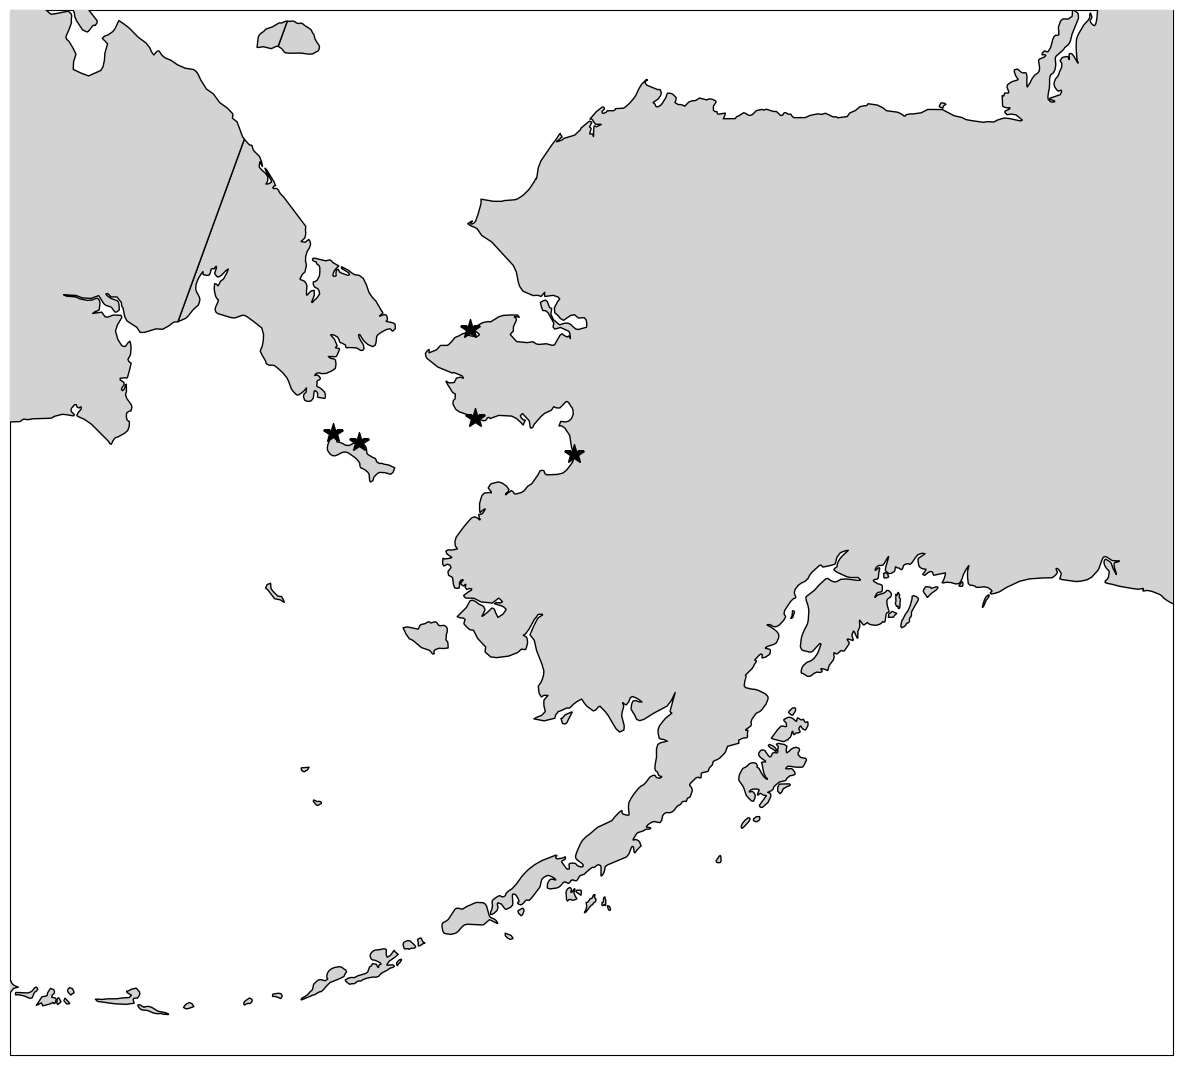

In [5]:
### Plot village locations
# create figure
fig = plt.figure(figsize=(15,15))
fout = 'fig_5_map'

fs = 15
# Make subplots - note it's nrow x ncol x index (starting upper left)
### First subplot: Alaska
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
ax.set_extent([lon_min, lon_max, lat_max, lat_min], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k',facecolor='lightgrey')

# add primary village locations and names
ax.plot(village_lons_1, village_lats_1, marker="*", markersize=15, linestyle='none', color='black',zorder=100,transform=ccrs.PlateCarree())

# add label
#ax.text(147.0,66.0,"d)",fontsize=20,color='black',zorder=100,transform=ccrs.PlateCarree())

# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)